In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load historical cloud spending data
df = pd.read_csv("data/historical_cloud_spending.csv")

# Display first five records
display(df.head())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column information
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

,billing_date,total_records,daily_billed_cost,daily_effective_cost,usage_billed_cost,daily_recurring_billed_cost
0,2026-07-01,56,1718.61,2087.03,1671.62,46.99
1,2026-07-02,56,1721.45,2089.87,1674.46,46.99
2,2026-07-03,56,1724.87,2093.29,1677.88,46.99
3,2026-07-04,52,1540.47,1908.89,1493.48,46.99
4,2026-07-05,52,1541.55,1909.97,1494.56,46.99


Dataset Shape: (92, 6)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   billing_date                 92 non-null     object 
 1   total_records                92 non-null     int64  
 2   daily_billed_cost            92 non-null     float64
 3   daily_effective_cost         92 non-null     float64
 4   usage_billed_cost            92 non-null     float64
 5   daily_recurring_billed_cost  92 non-null     float64
dtypes: float64(4), int64(1), object(1)
memory usage: 4.4+ KB

Missing Values:
billing_date                   0
total_records                  0
daily_billed_cost              0
daily_effective_cost           0
usage_billed_cost              0
daily_recurring_billed_cost    0
dtype: int64


In [2]:
# Convert billing_date to datetime
df['billing_date'] = pd.to_datetime(df['billing_date'])

# Sort data chronologically
df = df.sort_values('billing_date').reset_index(drop=True)

# Check duplicate dates
print("Duplicate Dates:", df['billing_date'].duplicated().sum())

# Check date range
print("First Billing Date:", df['billing_date'].min())
print("Last Billing Date:", df['billing_date'].max())

# Check missing dates
expected_dates = pd.date_range(
    start=df['billing_date'].min(),
    end=df['billing_date'].max(),
    freq='D'
)

missing_dates = expected_dates.difference(df['billing_date'])

print("Total Expected Days:", len(expected_dates))
print("Missing Dates:", len(missing_dates))

# Statistical summary
display(df.describe().round(2))

Duplicate Dates: 0
First Billing Date: 2026-07-01 00:00:00
Last Billing Date: 2026-09-30 00:00:00
Total Expected Days: 92
Missing Dates: 0


,billing_date,total_records,daily_billed_cost,daily_effective_cost,usage_billed_cost,daily_recurring_billed_cost
count,92,92.00,92.00,92.00,92.00,92.00
mean,2026-08-15 12:00:00,48.02,1778.33,2147.11,1731.34,46.99
min,2026-07-01 00:00:00,40.00,1540.47,1908.89,1493.48,46.99
25%,2026-07-23 18:00:00,42.00,1593.74,1963.12,1546.75,46.99
50%,2026-08-15 12:00:00,42.00,1735.26,2103.74,1688.26,46.99
75%,2026-09-07 06:00:00,56.00,1764.26,2133.64,1717.27,46.99
max,2026-09-30 00:00:00,56.00,5058.45,5427.97,5011.46,46.99
std,NaN,6.94,440.26,440.41,440.26,0.00


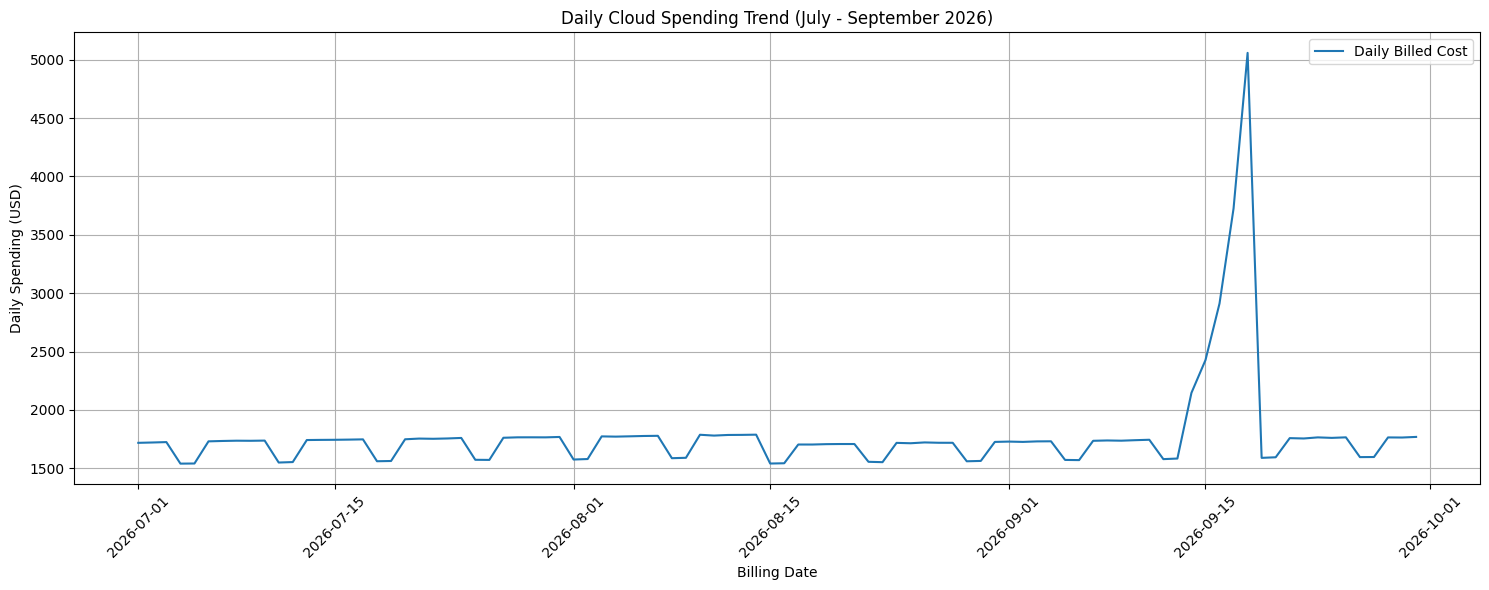

In [3]:
# Daily Cloud Spending Trend

plt.figure(figsize=(15, 6))

plt.plot(
    df['billing_date'],
    df['daily_billed_cost'],
    label='Daily Billed Cost'
)

plt.title('Daily Cloud Spending Trend (July - September 2026)')
plt.xlabel('Billing Date')
plt.ylabel('Daily Spending (USD)')

plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

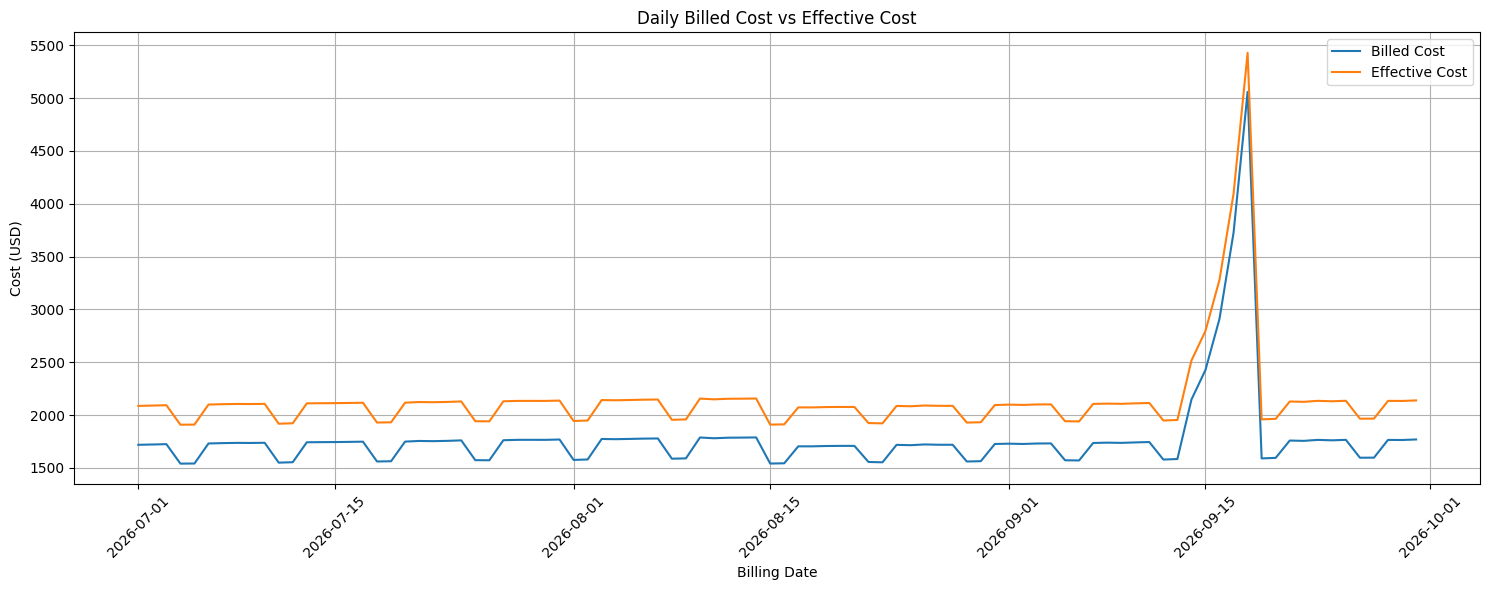

In [4]:
plt.figure(figsize=(15, 6))

plt.plot(
    df['billing_date'],
    df['daily_billed_cost'],
    label='Billed Cost'
)

plt.plot(
    df['billing_date'],
    df['daily_effective_cost'],
    label='Effective Cost'
)

plt.title('Daily Billed Cost vs Effective Cost')
plt.xlabel('Billing Date')
plt.ylabel('Cost (USD)')

plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

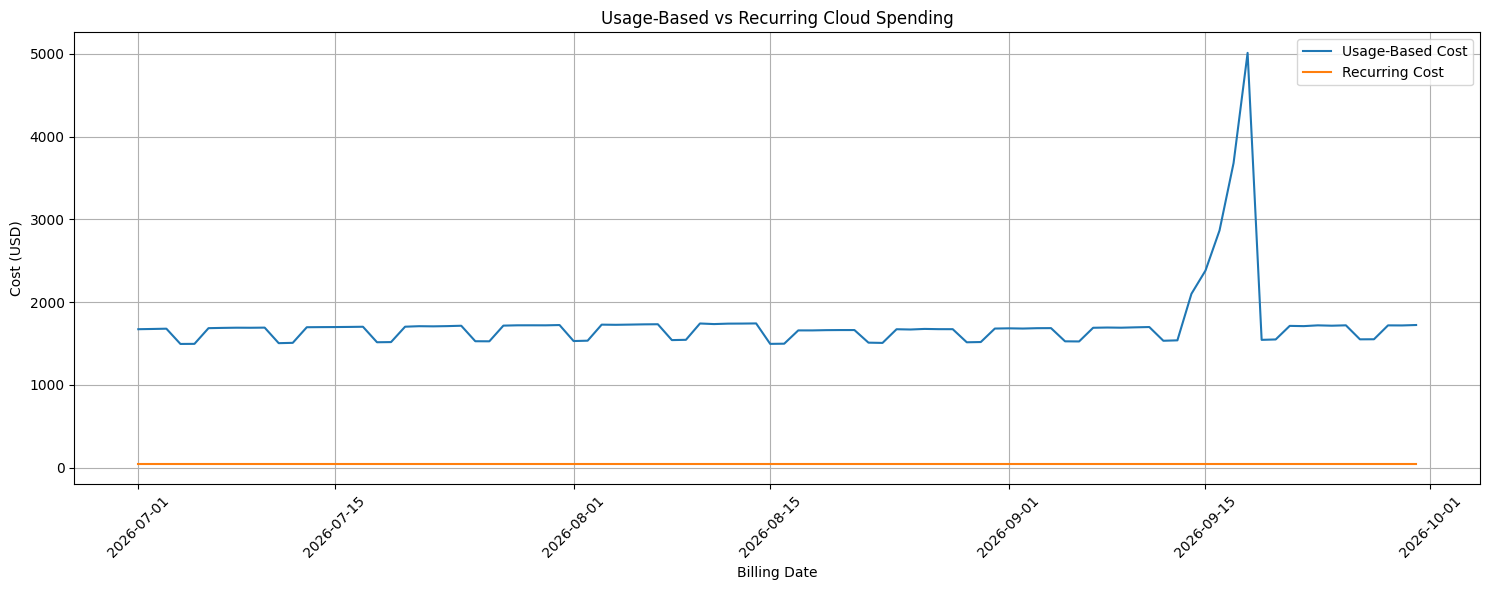

In [5]:
plt.figure(figsize=(15, 6))

plt.plot(
    df['billing_date'],
    df['usage_billed_cost'],
    label='Usage-Based Cost'
)

plt.plot(
    df['billing_date'],
    df['daily_recurring_billed_cost'],
    label='Recurring Cost'
)

plt.title('Usage-Based vs Recurring Cloud Spending')
plt.xlabel('Billing Date')
plt.ylabel('Cost (USD)')

plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()